# Polynominal Regression

Polynomial regression is a type of regression analysis in which the relationship between the independent variable(s) and the dependent variable is modeled as an nth-degree polynomial. Unlike simple linear regression, where the relationship is modeled as a straight line, polynomial regression allows for more complex, curved relationships to be captured. It is particularly useful when the relationship between the variables is not linear but exhibits some degree of curvature or nonlinearity.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
import pandas as pd

data = {
    'Position': [
        'Business Analyst', 'Junior Consultant', 'Senior Consultant',
        'Manager', 'Country Manager', 'Region Manager',
        'Partner', 'Senior Partner', 'C-level', 'CEO'
    ],
    'Level': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'Salary': [45000, 50000, 60000, 80000, 110000, 150000, 200000, 300000, 500000, 1000000]
}

df = pd.DataFrame(data)

df

,Position,Level,Salary
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000
5,Region Manager,6,150000
6,Partner,7,200000
7,Senior Partner,8,300000
8,C-level,9,500000
9,CEO,10,1000000


In [3]:
df = pd.read_csv('Position_Salaries.csv')

In [4]:
df

,Position,Level,Salary
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000
5,Region Manager,6,150000
6,Partner,7,200000
7,Senior Partner,8,300000
8,C-level,9,500000
9,CEO,10,1000000


- .iloc[:, 1:2] is used to select a subset of the data within the DataFrame.
- .values is used to retrieve the values of the selected subset as a NumPy array.


This is a common operation when you want to isolate and work with specific columns of data within a DataFrame for further analysis or modeling.

In [5]:
features = df.iloc[:, 1:2].values
features

array([[ 1],
       [ 2],
       [ 3],
       [ 4],
       [ 5],
       [ 6],
       [ 7],
       [ 8],
       [ 9],
       [10]])

In [6]:
labels = df.iloc[:, 2:].values
labels

array([[  45000],
       [  50000],
       [  60000],
       [  80000],
       [ 110000],
       [ 150000],
       [ 200000],
       [ 300000],
       [ 500000],
       [1000000]])

This code generates a scatter plot that visually shows the relationship between the "Level of experience" (on the x-axis) and "Salary" (on the y-axis). Scatter plots are commonly used for visualizing the distribution of data points and identifying potential patterns or trends in the data, especially when you want to see how two variables are related.

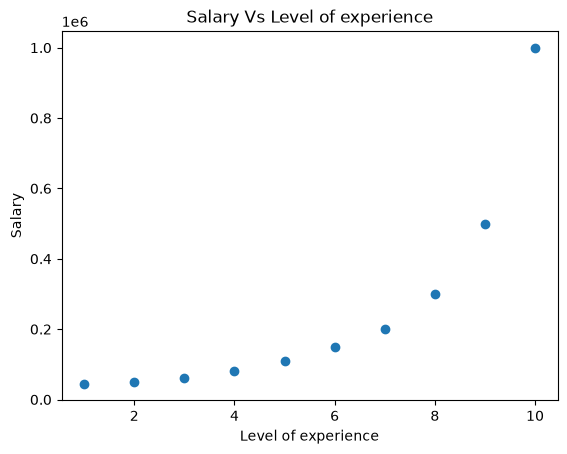

In [7]:
plt.scatter (features, labels)
plt.xlabel('Level of experience')
plt.ylabel('Salary')
plt.title('Salary Vs Level of experience')
plt.show()

- The __'degree'__ parameter specifies that you want to create polynomial combinations of your original features up to the third degree. This transformation is necessary when you suspect that the relationship between the features and the target variable is nonlinear and can be better captured by a polynomial function.

- __'Fit_transform'__ is a common method used in scikit-learn (sklearn) and other machine learning libraries, typically within the context of data preprocessing and feature engineering. It is used when you want to both "fit" a transformation to your data and then immediately "transform" the data using that fitted transformation.

    - __Fit__: When you "fit" a transformation to your data, you are essentially estimating the parameters or characteristics of that transformation based on your data.
    - __Transform__: After fitting the transformation, you apply it to your data. The "transform" step takes the data and applies the transformation, resulting in a modified dataset. 

In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

#fitting the linear regression line to the dataset
# Create a LinearRegression instance
linreg = LinearRegression()
# Fit the linear regression model to features and labels
linreg.fit(features, labels)

#fitting the polynomial regression line to the dataset
# Create a PolynomialFeatures instance with a degree of 3
poly = PolynomialFeatures(degree = 3)

# Transform the original features into polynomial features
X_poly = poly.fit_transform(features)

# Fit the polynomial features to the labels
poly.fit(X_poly, labels)

# Create another LinearRegression instance
linreg2 = LinearRegression()

# Fit a linear regression model to the polynomial features and labels
linreg2.fit(X_poly, labels)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 4)","[[ 0. ,180664.34,-48548.95, 4120.05]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[-121333.33]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](4,)","[1036.18, 16.62, 0.67, 0. ]"


In [9]:
# Prediction using Linear Regression
labels_pred = linreg.predict(features)
labels_pred

array([[-114454.54545455],
       [ -33575.75757576],
       [  47303.03030303],
       [ 128181.81818182],
       [ 209060.60606061],
       [ 289939.39393939],
       [ 370818.18181818],
       [ 451696.96969697],
       [ 532575.75757576],
       [ 613454.54545455]])

In [10]:
#R square value for linear regression
from sklearn.metrics import r2_score

r2 = r2_score(labels ,labels_pred)

r2

0.6690412331929895

In [11]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

# Assuming labels are your true values and labels_pred are your predicted values
rmse = np.sqrt(mean_squared_error(labels, labels_pred))
mae = mean_absolute_error(labels, labels_pred)

print(f'RMSE: {rmse:.3f}')
print(f'MAE: {mae:.3f}')


RMSE: 163388.735
MAE: 128454.545


In [12]:
#prediction using polynomial regression
labels_pred2 = linreg2.predict(X_poly)
labels_pred2

array([[ 14902.09790211],
       [ 78759.90675991],
       [ 94960.37296037],
       [ 88223.77622378],
       [ 83270.3962704 ],
       [104820.51282052],
       [177594.40559441],
       [326312.35431236],
       [575694.63869463],
       [950461.53846152]])

In [13]:
#R square value using polynomial
from sklearn.metrics import r2_score

r2 = r2_score(labels ,labels_pred2)

r2

0.9812097727913366

**Please find the rmse and mae for polynomial in below line.**

In [14]:
#write your code here.

In [15]:
labels

array([[  45000],
       [  50000],
       [  60000],
       [  80000],
       [ 110000],
       [ 150000],
       [ 200000],
       [ 300000],
       [ 500000],
       [1000000]])

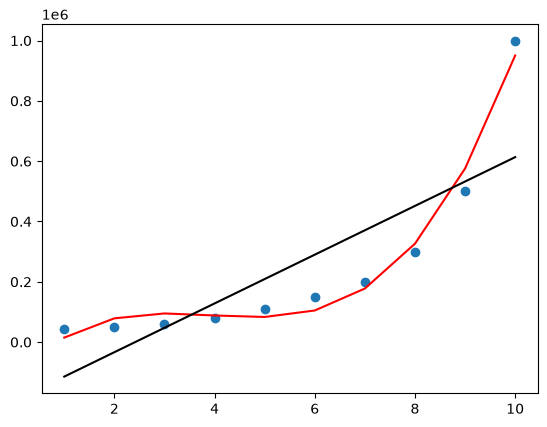

In [16]:
plt.scatter(features, labels)
plt.plot(features, labels_pred2, c='r')
plt.plot(features,labels_pred, c='black')
plt.show()

In [17]:
features = df['Position'].values
features

<StringArray>
[ 'Business Analyst', 'Junior Consultant', 'Senior Consultant',
           'Manager',   'Country Manager',    'Region Manager',
           'Partner',    'Senior Partner',           'C-level',
               'CEO']
Length: 10, dtype: str

In [18]:
x1 = pd.DataFrame(features) 
y1 = pd.DataFrame(labels_pred)

df1 = pd.concat([x1,y1], axis=1, keys=['Position','salary_pred_Lin']) 
df1

,Position,salary_pred_Lin
,0,0
0,Business Analyst,-114454.545455
1,Junior Consultant,-33575.757576
2,Senior Consultant,47303.030303
3,Manager,128181.818182
4,Country Manager,209060.606061
5,Region Manager,289939.393939
6,Partner,370818.181818
7,Senior Partner,451696.969697
8,C-level,532575.757576


In [19]:
x1 = pd.DataFrame(features) 
y1 =pd.DataFrame(labels_pred2)

df2 = pd.concat([x1,y1], axis=1, keys=['Position','salary_pred_poly']) 
df2

,Position,salary_pred_poly
,0,0
0,Business Analyst,14902.097902
1,Junior Consultant,78759.906760
2,Senior Consultant,94960.372960
3,Manager,88223.776224
4,Country Manager,83270.396270
5,Region Manager,104820.512821
6,Partner,177594.405594
7,Senior Partner,326312.354312
8,C-level,575694.638695


In [20]:
#Merging the dataframes

pd.merge(df2,df1, how='inner')

,Position,salary_pred_poly,salary_pred_Lin
,0,0,0
0,Business Analyst,14902.097902,-114454.545455
1,Junior Consultant,78759.906760,-33575.757576
2,Senior Consultant,94960.372960,47303.030303
3,Manager,88223.776224,128181.818182
4,Country Manager,83270.396270,209060.606061
5,Region Manager,104820.512821,289939.393939
6,Partner,177594.405594,370818.181818
7,Senior Partner,326312.354312,451696.969697
8,C-level,575694.638695,532575.757576


In [21]:
#To predict the salary for the given Level of experience using polynomial

linreg2.predict(poly.fit_transform([[8.5]]))


array([[436875.43706293]])

In [22]:
#To predict the salary for the level 8.5 using linear regression

import numpy as np

linreg.predict(np.array([ [8.5] ]) )

array([[492136.36363636]])

**Can you predict the other values in the same dataset using both the linear and polynomial regression and find out the difference?**

In [23]:
# Write your code here